In [2]:
import os
from pathlib import Path
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
from PIL import Image
import cv2

In [3]:
BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATASET_DIR = BASE_DIR / "dataset"
TRAIN_DIR = DATASET_DIR / "Training"
TEST_DIR = DATASET_DIR / "Testing"
print("Project Base Directory:", BASE_DIR)
print("Training Directory Exists:", TRAIN_DIR.exists())
print("Testing Directory Exists: ", TEST_DIR.exists())

Project Base Directory: d:\Brain_Tumor
Training Directory Exists: True
Testing Directory Exists:  True


In [4]:
import pandas as pd


In [9]:
import pandas as pd

# 1. Automatically detect all 4 class folder names
CLASSES = sorted([d.name for d in TRAIN_DIR.iterdir() if d.is_dir()])

# 2. List to store row dictionaries
data_counts = []

for folder in CLASSES:
    train_count = len(list((TRAIN_DIR / folder).glob("*.*")))
    test_count = len(list((TEST_DIR / folder).glob("*.*")))
    total = train_count + test_count
    
    data_counts.append({
        "Class": folder,
        "Training Images": train_count,
        "Testing Images": test_count,
        "Total Images": total
    })

# 3. Convert into a DataFrame for easy viewing
df_counts = pd.DataFrame(data_counts)

# 4. Add a "Total" summary row at the bottom
total_row = pd.DataFrame([{
    "Class": "TOTAL",
    "Training Images": df_counts["Training Images"].sum(),
    "Testing Images": df_counts["Testing Images"].sum(),
    "Total Images": df_counts["Total Images"].sum()
}])
df_counts = pd.concat([df_counts, total_row], ignore_index=True)

df_counts



,Class,Training Images,Testing Images,Total Images
0,glioma,1400,400,1800
1,meningioma,1400,400,1800
2,notumor,1400,400,1800
3,pituitary,1400,400,1800
4,TOTAL,5600,1600,7200


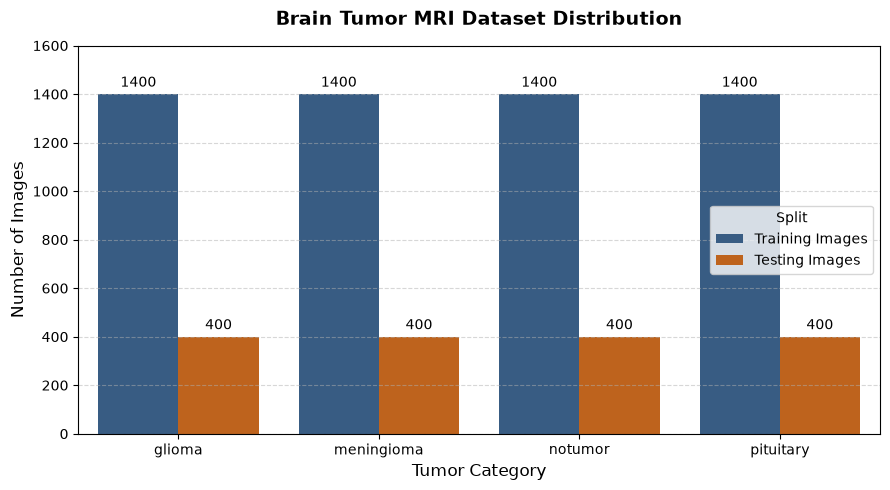

In [10]:
# Filter out the 'TOTAL' row so we only plot the 4 classes
plot_df = df_counts[df_counts["Class"] != "TOTAL"].copy()

# Melt the DataFrame so Seaborn can easily plot side-by-side bars
melted_df = pd.melt(
    plot_df, 
    id_vars=["Class"], 
    value_vars=["Training Images", "Testing Images"],
    var_name="Split", 
    value_name="Count"
)

plt.figure(figsize=(9, 5))
palette = {"Training Images": "#2b5c8f", "Testing Images": "#d95f02"}

ax = sns.barplot(data=melted_df, x="Class", y="Count", hue="Split", palette=palette)

# Add data labels on top of the bars
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f"{int(height)}",
            (p.get_x() + p.get_width() / 2., height),
            ha="center", va="bottom", fontsize=10, xytext=(0, 3),
            textcoords="offset points"
        )

plt.title("Brain Tumor MRI Dataset Distribution", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Tumor Category", fontsize=12)
plt.ylabel("Number of Images", fontsize=12)
plt.ylim(0, 1600)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


In [11]:
from collections import Counter

def inspect_dataset(directory):
    total_checked = 0
    corrupt_files = []
    formats = Counter()
    modes = Counter()
    resolutions = Counter()
    
    # Iterate through all files in the directory recursively
    for filepath in Path(directory).rglob("*.*"):
        if filepath.is_file():
            total_checked += 1
            try:
                # Open with PIL (fast header read without loading all pixels into memory)
                with Image.open(filepath) as img:
                    img.verify() # Checks if the image file is broken/corrupted
                
                # Reopen to read size and mode (verify() closes or resets the file pointer)
                with Image.open(filepath) as img:
                    formats[img.format] += 1
                    modes[img.mode] += 1
                    resolutions[img.size] += 1
                    
            except Exception as e:
                corrupt_files.append((str(filepath), str(e)))
                
    return {
        "total_checked": total_checked,
        "corrupt_files": corrupt_files,
        "formats": formats,
        "modes": modes,
        "resolutions": resolutions
    }

print("Scanning all images in dataset for integrity and dimensions...")
stats = inspect_dataset(DATASET_DIR)

print(f"\n--- Integrity Report ---")
print(f"Total Images Checked : {stats['total_checked']}")
print(f"Corrupt Files Found  : {len(stats['corrupt_files'])}")
if stats['corrupt_files']:
    print(f"Corrupt Files List   : {stats['corrupt_files']}")

print(f"\n--- File Formats ---")
for fmt, count in stats['formats'].items():
    print(f"  {fmt}: {count}")

print(f"\n--- Color Modes ---")
for mode, count in stats['modes'].items():
    meaning = "Grayscale (1 channel)" if mode == "L" else "Color (3 channels)" if mode == "RGB" else mode
    print(f"  {mode} ({meaning}): {count}")

print(f"\n--- Top 5 Most Common Resolutions (Width x Height) ---")
for res, count in stats['resolutions'].most_common(5):
    print(f"  {res[0]}x{res[1]} : {count} images")

print(f"Total Unique Resolutions across dataset: {len(stats['resolutions'])}")


Scanning all images in dataset for integrity and dimensions...

--- Integrity Report ---
Total Images Checked : 7200
Corrupt Files Found  : 0

--- File Formats ---
  JPEG: 7196
  PNG: 4

--- Color Modes ---
  RGB (Color (3 channels)): 4129
  L (Grayscale (1 channel)): 3067
  RGBA (RGBA): 3
  P (P): 1

--- Top 5 Most Common Resolutions (Width x Height) ---
  512x512 : 5014 images
  225x225 : 338 images
  630x630 : 90 images
  201x251 : 57 images
  228x221 : 51 images
Total Unique Resolutions across dataset: 447


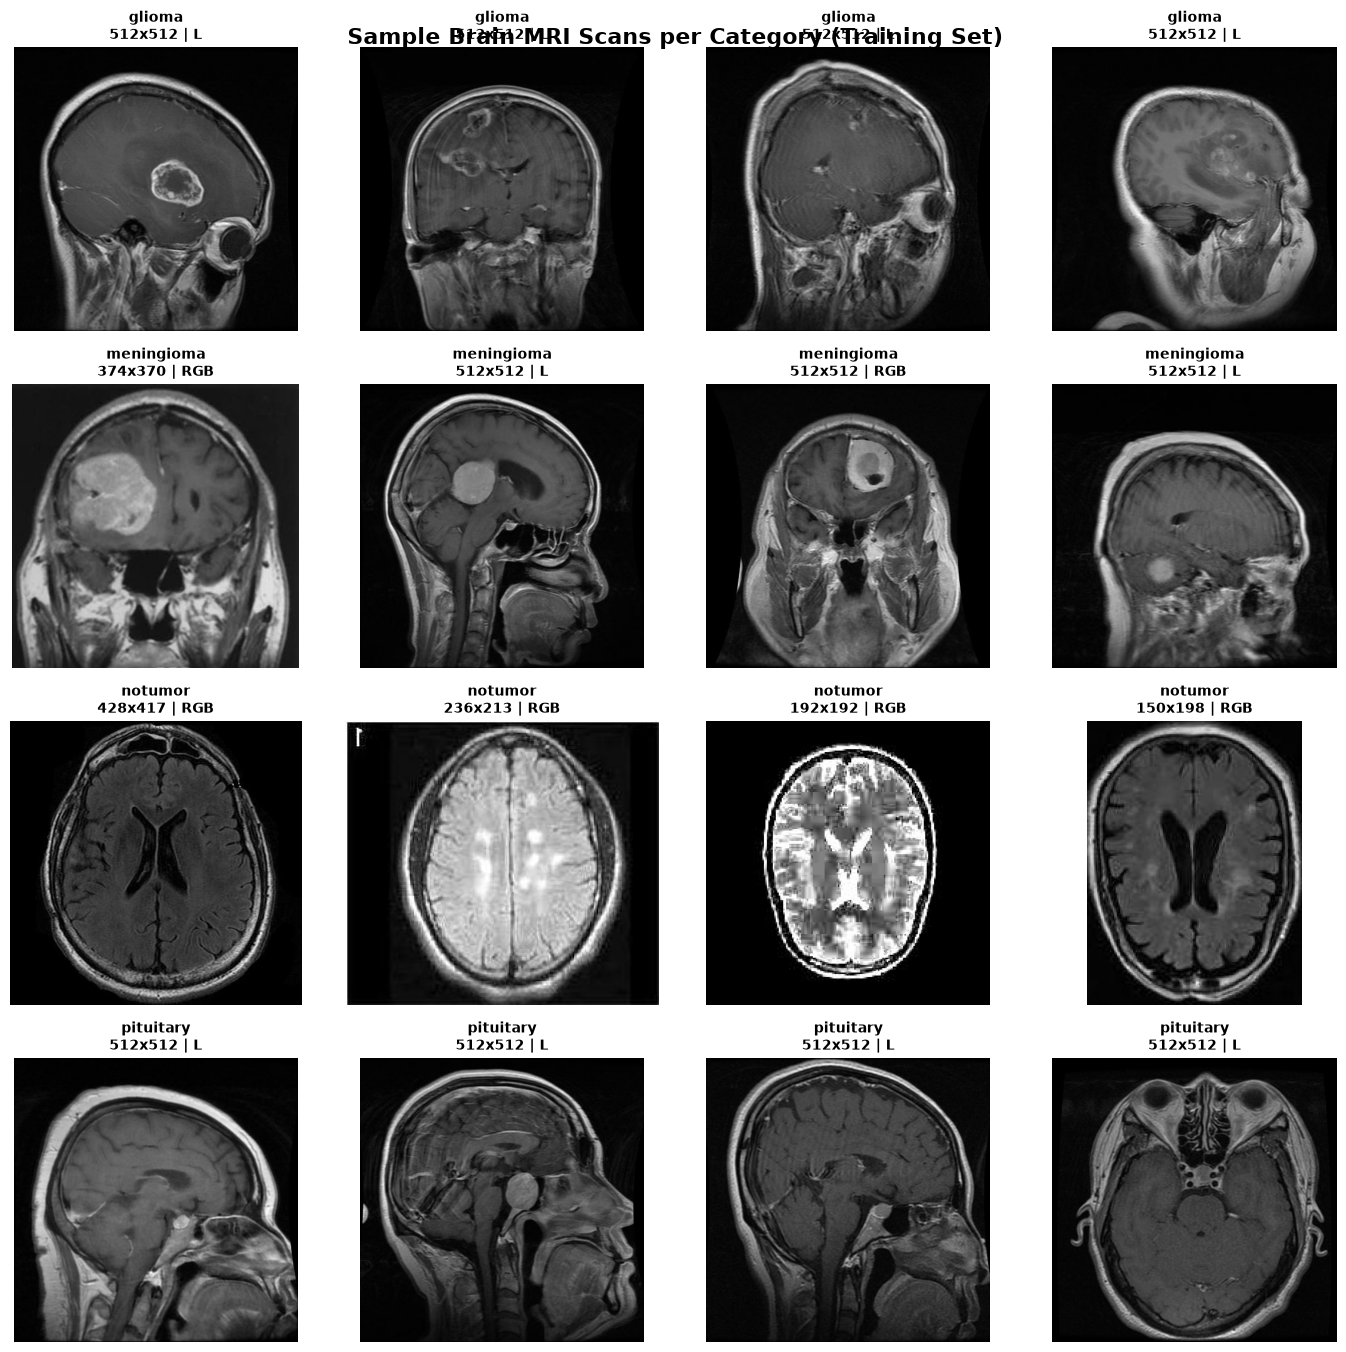

In [12]:
import random

# Set random seed for reproducibility
random.seed(42)

samples_per_class = 4
fig, axes = plt.subplots(len(CLASSES), samples_per_class, figsize=(14, 14))

for row_idx, cls in enumerate(CLASSES):
    class_folder = TRAIN_DIR / cls
    all_images = list(class_folder.glob("*.*"))
    selected_samples = random.sample(all_images, samples_per_class)
    
    for col_idx, img_path in enumerate(selected_samples):
        ax = axes[row_idx, col_idx]
        
        # Load image with PIL to inspect native properties
        with Image.open(img_path) as pil_img:
            width, height = pil_img.size
            mode = pil_img.mode
            
            # Convert to RGB so matplotlib displays all consistently
            display_img = pil_img.convert("RGB")
            
        ax.imshow(display_img)
        ax.set_title(f"{cls}\n{width}x{height} | {mode}", fontsize=10, fontweight="bold")
        ax.axis("off")

plt.suptitle("Sample Brain MRI Scans per Category (Training Set)", fontsize=16, fontweight="bold", y=0.95)
plt.tight_layout()
plt.show()


In [13]:
import hashlib

def compute_image_hash(filepath):
    """Computes MD5 hash of an image file to detect exact duplicates."""
    hasher = hashlib.md5()
    with open(filepath, "rb") as f:
        # Read in 64KB chunks for memory efficiency
        buf = f.read(65536)
        while len(buf) > 0:
            hasher.update(buf)
            buf = f.read(65536)
    return hasher.hexdigest()

print("Calculating hashes across Training and Testing sets...")

train_hashes = {}
for path in TRAIN_DIR.rglob("*.*"):
    if path.is_file():
        h = compute_image_hash(path)
        train_hashes.setdefault(h, []).append(path)

test_hashes = {}
for path in TEST_DIR.rglob("*.*"):
    if path.is_file():
        h = compute_image_hash(path)
        test_hashes.setdefault(h, []).append(path)

# 1. Duplicates within Training set
train_internal_dups = {h: paths for h, paths in train_hashes.items() if len(paths) > 1}

# 2. Duplicates within Testing set
test_internal_dups = {h: paths for h, paths in test_hashes.items() if len(paths) > 1}

# 3. Cross-split duplicates (DATA LEAKAGE)
leaked_hashes = set(train_hashes.keys()).intersection(set(test_hashes.keys()))

print("\n--- Duplicate & Data Leakage Report ---")
print(f"Total Unique Images in Training : {len(train_hashes)} (out of 5600 files)")
print(f"Duplicate Images within Training: {sum(len(p)-1 for p in train_internal_dups.values())}")

print(f"Total Unique Images in Testing  : {len(test_hashes)} (out of 1600 files)")
print(f"Duplicate Images within Testing : {sum(len(p)-1 for p in test_internal_dups.values())}")

print(f"\n🚨 DATA LEAKAGE ALERT 🚨")
print(f"Images present in BOTH Training and Testing: {len(leaked_hashes)}")

if len(leaked_hashes) > 0:
    print(f"Example leaked pair:")
    example_hash = list(leaked_hashes)[0]
    print(f"  In Training: {train_hashes[example_hash][0].name} (Class: {train_hashes[example_hash][0].parent.name})")
    print(f"  In Testing : {test_hashes[example_hash][0].name} (Class: {test_hashes[example_hash][0].parent.name})")
else:
    print("Zero data leakage detected between Training and Testing sets!")


Calculating hashes across Training and Testing sets...

--- Duplicate & Data Leakage Report ---
Total Unique Images in Training : 5429 (out of 5600 files)
Duplicate Images within Training: 171
Total Unique Images in Testing  : 1584 (out of 1600 files)
Duplicate Images within Testing : 16

🚨 DATA LEAKAGE ALERT 🚨
Images present in BOTH Training and Testing: 0
Zero data leakage detected between Training and Testing sets!


* Total Dataset Size & Split: (7,200 total: 5,600 train / 1,600 test).
* Class Balance: (Balanced: 4 classes with 1,400 train / 400 test each).
* Color Modes & Required Action: (Mixed: RGB, L, RGBA $\rightarrow$ must convert all to   RGB).
* Resolutions & Required Action: (447 unique sizes $\rightarrow$ must resize to standard $224 \times 224$).
* Data Leakage: (0 leaked images between Train and Test).